In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

DATA_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = ROOT / "results" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

file = DATA_DIR / "hakaluki_monthly_2019_2025.csv"

df = pd.read_csv(file)
df["period"] = df["period"].astype(str)
df = df.sort_values("period").reset_index(drop=True)

expected = pd.period_range(
    "2019-01", "2025-12", freq="M"
).astype(str)

print("Total records:", len(df))
print("Total variables:", len(df.columns))
print("Missing periods:", sorted(set(expected) - set(df["period"])))
print("Duplicate periods:", df["period"].duplicated().sum())

# Variable availability
quality = pd.DataFrame({
    "variable": df.columns,
    "valid_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_percent": (
        df.isna().mean().values * 100
    ).round(2)
})

quality.to_csv(
    OUTPUT_DIR / "complete_data_quality_2019_2025.csv",
    index=False
)

# Check radar observation availability
print("\nSentinel-1 scenes per month:")
print(df["s1_scenes"].describe())

# Check cache consistency
if "cache_fingerprint" in df.columns:
    print("\nUnique processing fingerprints:")
    print(df["cache_fingerprint"].value_counts(dropna=False))

# Check processing status
if "result_status" in df.columns:
    print("\nProcessing status:")
    print(df["result_status"].value_counts(dropna=False))

# Check classification bounds
if {
    "water_area_low_km2",
    "water_area_km2",
    "water_area_high_km2"
}.issubset(df.columns):

    invalid_bounds = df[
        (df["water_area_low_km2"] > df["water_area_km2"]) |
        (df["water_area_km2"] > df["water_area_high_km2"])
    ]

    print("\nInvalid water sensitivity bounds:", len(invalid_bounds))

# Check water area relative to study polygon
AREA_KM2 = 172.2907

excess = df[df["water_area_km2"] > AREA_KM2]

print("Months with water area exceeding study area:", len(excess))

display(quality)

print("\nQuality report saved successfully.")


Total records: 84
Total variables: 30
Missing periods: []
Duplicate periods: 0

Sentinel-1 scenes per month:
count    84.000000
mean      2.547619
std       0.524227
min       1.000000
25%       2.000000
50%       3.000000
75%       3.000000
max       3.000000
Name: s1_scenes, dtype: float64

Unique processing fingerprints:
cache_fingerprint
11d6b74f88543283fc05    84
Name: count, dtype: int64

Processing status:
result_status
preliminary_unvalidated    84
Name: count, dtype: int64

Invalid water sensitivity bounds: 0
Months with water area exceeding study area: 0


,variable,valid_count,missing_count,missing_percent
0,year,84,0,0.00
1,month,84,0,0.00
2,period,84,0,0.00
3,start,84,0,0.00
4,end,84,0,0.00
5,s1_scenes,84,0,0.00
6,water_threshold_db,84,0,0.00
7,water_area_km2,84,0,0.00
8,water_area_low_km2,84,0,0.00
9,water_area_high_km2,84,0,0.00



Quality report saved successfully.


# 02 — Exploratory statistical analysis and honest model benchmarking

This notebook reads **real Earth Engine-generated CSV files** from Notebook 01. It produces descriptive plots and, only if sufficient valid multi-year data exist, year-blocked model comparisons.

Prediction target: **regional atmospheric XCH₄ difference relative to an exploratory reference ring**, not wetland methane emission flux. The ring is not wind-matched; conclusions are associations pending atmospheric-transport analysis. No synthetic training data are generated.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path(r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project")
sys.path.insert(0,str(ROOT))
from src.hakaluki_core import project_paths
P=project_paths(ROOT)
files=sorted(P['processed'].glob('monthly_20??-??.csv'))
assert files,'No real GEE monthly CSVs found. Run notebooks 00 and 01 first.'
DF=pd.concat([pd.read_csv(f) for f in files],ignore_index=True)
DF=DF.drop_duplicates('period').sort_values(['year','month']).reset_index(drop=True)
DF['date']=pd.to_datetime(DF['period']+'-01')
print('Real monthly records:',len(DF),'Years:',sorted(DF['year'].unique().tolist()))
display(DF.head())

Real monthly records: 84 Years: [2019, 2020, 2021, 2022, 2023, 2024, 2025]


,year,month,period,start,end,s1_scenes,water_threshold_db,water_area_km2,water_area_low_km2,water_area_high_km2,...,dw_water_km2,dw_flooded_vegetation_km2,dw_crops_km2,dw_valid_class_area_km2,s2_scene_count,ndvi_s2_mean,mndwi_s2_mean,result_status,cache_fingerprint,date
0,2019,1,2019-01,2019-01-01,2019-02-01,3,-16.793149,38.424266,34.183032,46.000658,...,51.797364,63.060943,28.775363,172.385273,24,0.286941,0.034206,preliminary_unvalidated,11d6b74f88543283fc05,2019-01-01
1,2019,2,2019-02,2019-02-01,2019-03-01,2,-16.398057,30.118934,28.321768,33.361474,...,42.389237,28.132879,41.364400,172.385273,24,0.423449,-0.150030,preliminary_unvalidated,11d6b74f88543283fc05,2019-02-01
2,2019,3,2019-03,2019-03-01,2019-04-01,3,-16.000991,32.538421,30.143240,37.309936,...,44.177634,9.408739,58.849916,172.385273,25,0.455000,-0.188747,preliminary_unvalidated,11d6b74f88543283fc05,2019-03-01
3,2019,4,2019-04,2019-04-01,2019-05-01,2,-13.195970,54.465061,47.844008,66.228730,...,59.931130,47.098074,37.163073,172.385273,26,0.274553,-0.041663,preliminary_unvalidated,11d6b74f88543283fc05,2019-04-01
4,2019,5,2019-05,2019-05-01,2019-06-01,3,-14.003889,76.481441,71.763893,83.114411,...,117.001209,28.826233,2.218052,163.762251,24,0.005136,0.149897,preliminary_unvalidated,11d6b74f88543283fc05,2019-05-01


## A. Observation gaps and quality audit

The number of TROPOMI image tiles and the gridded coverage fraction **do not equal** the number of independent methane retrieval footprints. Reject months with missing target or meteorological information; use additional acquisition-level diagnostics in the final paper.

,variable,available,missing
0,water_area_km2,84,0
1,rain_chirps_mm,84,0
2,temp2m_era5_c,84,0
3,ch4_xch4_ppb_roi,69,15
4,ch4_xch4_ppb_ring,74,10
5,ch4_roi_minus_ring_ppb,68,16


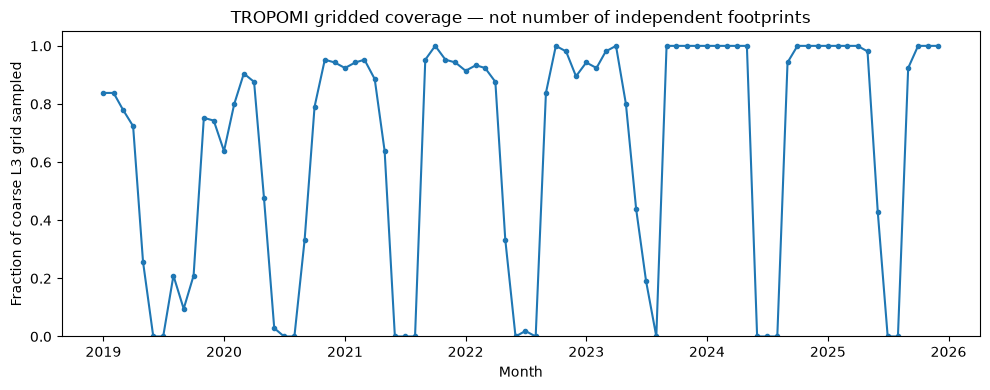

In [3]:
qa_fields=['water_area_km2','rain_chirps_mm','temp2m_era5_c',
           'ch4_xch4_ppb_roi','ch4_xch4_ppb_ring','ch4_roi_minus_ring_ppb']
qa=pd.DataFrame({'variable':qa_fields,'available':DF[qa_fields].notna().sum().values,
                 'missing':DF[qa_fields].isna().sum().values})
qa.to_csv(P['tables']/'missingness_by_variable.csv',index=False)
display(qa)
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(DF['date'],DF['ch4_l3_grid_coverage_fraction'],marker='.')
ax.set(xlabel='Month',ylabel='Fraction of coarse L3 grid sampled',ylim=(0,1.05),
       title='TROPOMI gridded coverage — not number of independent footprints')
fig.tight_layout();fig.savefig(P['figures']/'tropomi_l3_coverage.png',dpi=170)
plt.show()

## B. Month-of-year adjusted associations

Subtract the monthly climatological mean separately for each variable, reducing a simple seasonal confounder. This is **not** causal adjustment for atmospheric transport, rice paddies, or other emission sectors. A single year cannot support a multi-year seasonal climatology.

In [4]:
df=DF.copy()
if df['year'].nunique()>=3:
    for v in ['water_area_km2','rain_chirps_mm','ch4_roi_minus_ring_ppb']:
        df[v+'_seasonal_anomaly']=df[v]-df.groupby('month')[v].transform('mean')
    cols=['water_area_km2_seasonal_anomaly','rain_chirps_mm_seasonal_anomaly',
          'ch4_roi_minus_ring_ppb_seasonal_anomaly']
    print('Seasonally adjusted correlations (descriptive only):')
    display(df[cols].corr())
    df[cols+['period']].to_csv(P['tables']/'seasonally_adjusted_anomalies.csv',index=False)
else:
    print('At least three years recommended to calculate useful monthly seasonal anomalies.')

Seasonally adjusted correlations (descriptive only):


,water_area_km2_seasonal_anomaly,rain_chirps_mm_seasonal_anomaly,ch4_roi_minus_ring_ppb_seasonal_anomaly
water_area_km2_seasonal_anomaly,1.000000,0.32552,0.089812
rain_chirps_mm_seasonal_anomaly,0.325520,1.00000,-0.066270
ch4_roi_minus_ring_ppb_seasonal_anomaly,0.089812,-0.06627,1.000000


## C. Sensitivity of lagged monthly relationships

Simple lag checks at 0, 1, 2 months are **screening analyses**, not a formal distributed lag model. A future event-scale study should use suitable daily observation windows and temporal autocorrelation methods. No p-values are assigned to the exploratory screen.

In [5]:
lags=[]
if df['year'].nunique()>=3:
    for lag in range(0,3):
        aa=df['water_area_km2_seasonal_anomaly'].shift(lag)
        bb=df['ch4_roi_minus_ring_ppb_seasonal_anomaly']
        both=aa.notna()&bb.notna()
        r=aa[both].corr(bb[both]) if both.sum()>=12 else np.nan
        lags.append({'flood_leads_ch4_months':lag,'n_paired':int(both.sum()),'pearson_r':r})
    lag_results=pd.DataFrame(lags)
    display(lag_results)
    lag_results.to_csv(P['tables']/'monthly_lag_screen.csv',index=False)
else:
    print('Need multi-year data for an exploratory lag screen.')

,flood_leads_ch4_months,n_paired,pearson_r
0,0,68,0.089812
1,1,67,0.397594
2,2,66,0.289101


## D. Out-of-year prediction benchmark

The model only runs if at least four unique years and at least 36 complete monthly rows are available. Train on all but the most recent year, test on the most recent year. Real scientific evaluation should additionally use leave-one-year-out cross-validation and report results on withheld flood events; this cell is an initial benchmark.

**Models predict atmospheric methane anomaly, NOT CH₄ flux.**

In [6]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
FEATURES=['water_area_km2','rain_chirps_mm','temp2m_era5_c']
TARGET='ch4_roi_minus_ring_ppb'
usable=DF[['year','month']+FEATURES+[TARGET]].dropna().copy()
years=sorted(usable.year.unique())
if len(years)<4 or len(usable)<36:
    print(f'ML SKIPPED: {len(usable)} complete observations over {len(years)} years; do not pretend pilot data support robust ML.')
else:
    test_year=years[-1]
    train=usable[usable.year!=test_year]
    test=usable[usable.year==test_year]
    assert len(test)>=6, 'Not enough test months for credible evaluation.'
    Xtr,Xte=train[FEATURES],test[FEATURES]
    ytr,yte=train[TARGET],test[TARGET]
    by_month=train.groupby('month')[TARGET].mean()
    seasonal_baseline=test.month.map(by_month).fillna(ytr.mean()).to_numpy()
    model_list={
        'Seasonal baseline': None,
        'Random Forest':RandomForestRegressor(n_estimators=250,min_samples_leaf=4,random_state=42,n_jobs=-1),
        'Gradient Boosting':HistGradientBoostingRegressor(max_iter=180,max_leaf_nodes=5,l2_regularization=3,random_state=42),
    }
    scores=[]
    for name,model in model_list.items():
        if model is None:
            pred=seasonal_baseline
        else:
            model.fit(Xtr,ytr)
            pred=model.predict(Xte)
        scores.append({'model':name,'test_year':test_year,'n_test':len(test),
                       'mae_ppb':mean_absolute_error(yte,pred),
                       'rmse_ppb':np.sqrt(mean_squared_error(yte,pred))})
    results=pd.DataFrame(scores).sort_values('rmse_ppb')
    display(results)
    results.to_csv(P['tables']/'exploratory_year_holdout_models.csv',index=False)
    print('Do not interpret these models as independently calibrated wetland emission estimates.')

,model,test_year,n_test,mae_ppb,rmse_ppb
0,Seasonal baseline,2025,10,4.706268,5.821619
1,Random Forest,2025,10,6.740114,8.605667
2,Gradient Boosting,2025,10,6.418440,8.745723


Do not interpret these models as independently calibrated wetland emission estimates.


## E. Field calibration is preserved, not abandoned

When field measurements become available:

1. Preserve their original flux units and measurement method; reconcile mg CH₄ m⁻² h⁻¹ vs mg C–CH₄ m⁻² h⁻¹ rather than treating them as identical.
2. Geolocate the chamber/eddy-covariance footprint, habitat, flood phase, measurement timestamp, and quality flag.
3. Align imagery to measurement support and temporality, avoiding forced 10 m matches to coarse meteorology.
4. Build an **independent flux prediction model** using observed flux as target, then validate it with held-out sites and events.
5. Do not simply recalibrate atmospheric XCH₄ as flux by linear regression without assessing transport and background effects.

Template: `results/calibration/field_flux_template.csv`.

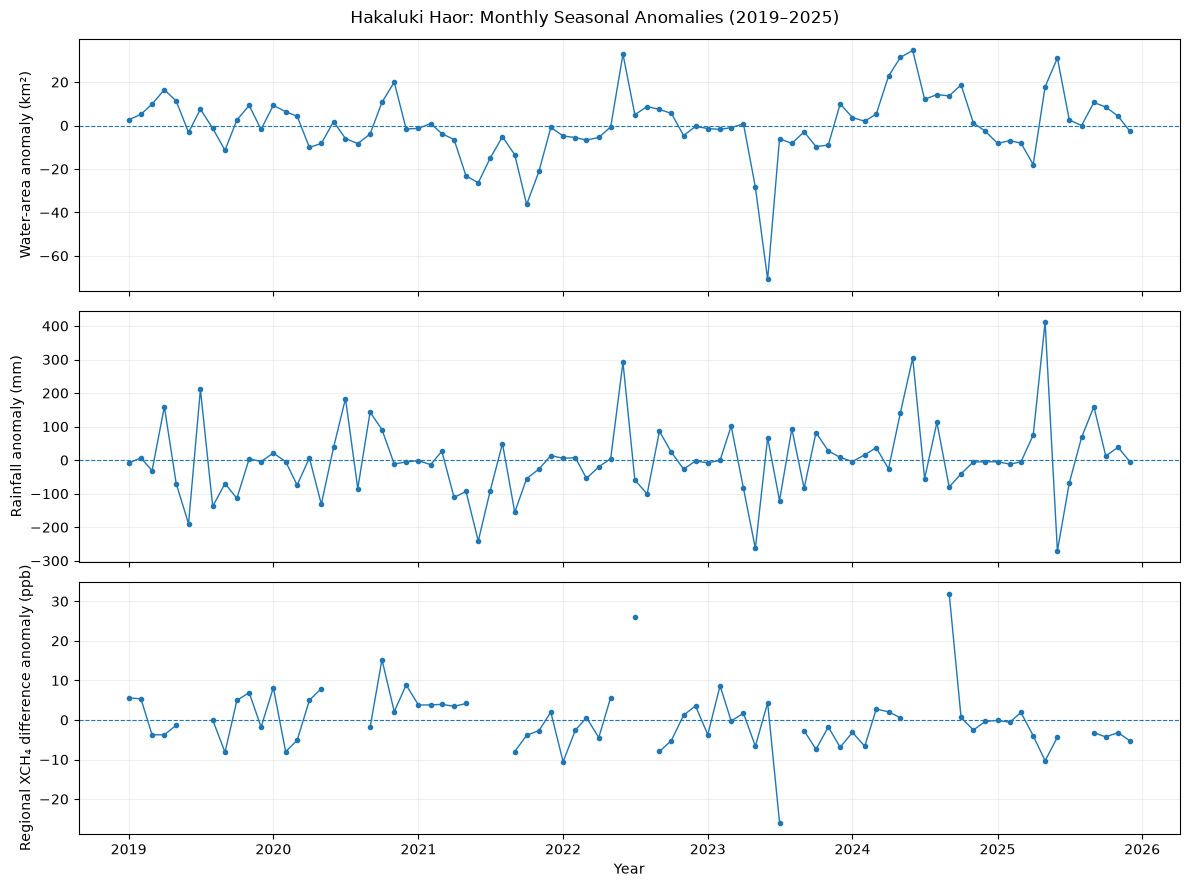

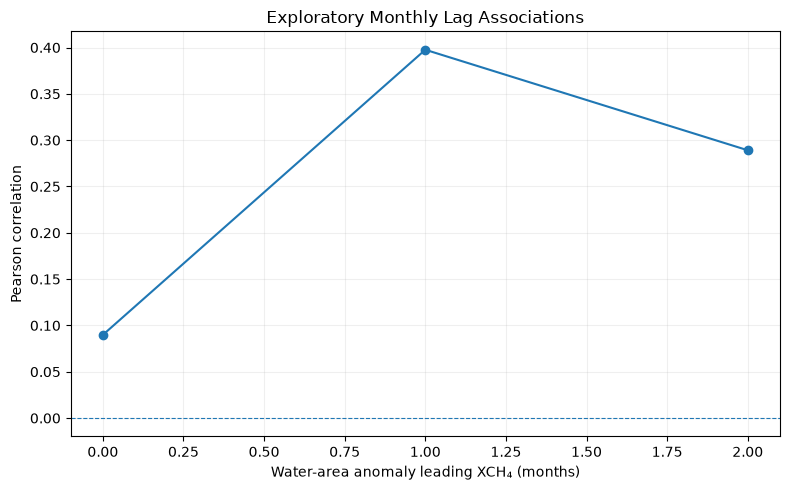

Figures saved to: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\figures


In [7]:

import matplotlib.pyplot as plt

OUT = ROOT / "results" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

# Plot seasonal anomalies
cols = [
    "water_area_km2_seasonal_anomaly",
    "rain_chirps_mm_seasonal_anomaly",
    "ch4_roi_minus_ring_ppb_seasonal_anomaly"
]

if all(c in df.columns for c in cols):
    fig, axes = plt.subplots(3, 1, figsize=(12, 9),
                            sharex=True)

    labels = [
        "Water-area anomaly (km²)",
        "Rainfall anomaly (mm)",
        "Regional XCH₄ difference anomaly (ppb)"
    ]

    for ax, col, label in zip(axes, cols, labels):
        ax.plot(df["date"], df[col], marker=".", linewidth=1)
        ax.axhline(0, linewidth=0.8, linestyle="--")
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)

    axes[-1].set_xlabel("Year")
    fig.suptitle(
        "Hakaluki Haor: Monthly Seasonal Anomalies (2019–2025)"
    )

    fig.tight_layout()
    fig.savefig(
        OUT / "hakaluki_seasonal_anomalies_2019_2025.png",
        dpi=300, bbox_inches="tight"
    )
    fig.savefig(
        OUT / "hakaluki_seasonal_anomalies_2019_2025.svg",
        bbox_inches="tight"
    )
    plt.show()

# Save the lag analysis figure
if "lag_results" in globals() and not lag_results.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(
        lag_results["flood_leads_ch4_months"],
        lag_results["pearson_r"],
        marker="o"
    )
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set(
        xlabel="Water-area anomaly leading XCH₄ (months)",
        ylabel="Pearson correlation",
        title="Exploratory Monthly Lag Associations"
    )
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(
        OUT / "hakaluki_methane_lag_screen.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

print("Figures saved to:", OUT)
